# 🤖 PREP_02 v5 — Analisis Sentimen IndoBERT (X2) dengan Label Manusia
## Tesis: Prediksi Volatilitas Return Saham Energi LQ45 — Ilda Nurida (ITS)

**Desain evaluasi (revisi reviewer):**
| Komponen | Isi |
|---|---|
| Data latih | Judul berlabel **manusia** (`anotasi_tambahan.xlsx`), 85% latih / 15% validasi untuk memilih checkpoint |
| Data uji | **172 judul tetap** berlabel manusia (Label_A) + LLM (Label_B) — tidak pernah dipakai untuk melatih atau memilih model |
| Acuan evaluasi | Leksikon, LLM, manusia, konsensus manusia–LLM |
| Output X2 | `03_dataset/processed/skor_sentimen_harian.csv` dan `sentiment_ready_for_merge.csv` |

**Jalankan berurutan dari atas ke bawah.** SEL G (evaluasi uji) cukup dijalankan **sekali**; hasilnya dilaporkan apa adanya.

## ⚙️ SEL A — Setup, Path, dan Seed

In [1]:
# ════ SEL A : SETUP ════
import warnings; warnings.filterwarnings('ignore')
import re, os, shutil
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path
from transformers import set_seed

SEED = 42
set_seed(SEED); np.random.seed(SEED)

ROOT = Path(r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026")
DIR_FINAL     = ROOT / "03_dataset" / "final"
DIR_PROCESSED = ROOT / "03_dataset" / "processed"
DIR_SENT      = ROOT / "02_preprocessing" / "sentimen_indobert"

# Input anotasi
PATH_LATIH = DIR_SENT / "output_sentimen"   / "anotasi_tambahan.xlsx"          # label manusia (data latih)
PATH_UJI   = DIR_SENT / "output_sentimen 1" / "anotasi_manual_LabelB_LLM.xlsx" # 172 judul uji (Label_A, Label_B)

# Output versi baru (hasil lama tidak tertimpa)
DIR_OUT    = DIR_SENT / "output_sentimen_v2_manual"
DIR_GAMBAR = DIR_OUT / "gambar"
DIR_MODEL  = DIR_OUT / "model_final"
for d in [DIR_OUT, DIR_GAMBAR, DIR_PROCESSED]:
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
LBL      = ['Negatif', 'Netral', 'Positif']
LABEL2ID = {l: i for i, l in enumerate(LBL)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
MAP_LBL  = {'positif': 'Positif', 'netral': 'Netral', 'negatif': 'Negatif'}

MODEL_BASE = 'indobenchmark/indobert-base-p2'
MAX_LEN    = 128
LATIH_ULANG = not DIR_MODEL.exists()   # False → pakai model tersimpan (tidak fine-tune ulang)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device     :", DEVICE)
print("Output     :", DIR_OUT)
print("Fine-tune  :", "YA (model belum ada)" if LATIH_ULANG else "TIDAK (memuat model_final tersimpan)")

Device     : cpu
Output     : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen_v2_manual
Fine-tune  : YA (model belum ada)


## 🗄️ SEL A2 — Cadangkan Hasil Versi Leksikon (otomatis dilewati bila sudah ada)

In [2]:
# ════ SEL A2 : BACKUP VERSI LAMA (sekali saja) ════
for src in [DIR_SENT / "output_sentimen 1", ROOT / "03_dataset"]:
    dst = src.with_name(src.name + "_v1_leksikon")
    if dst.exists():
        print("Sudah ada, dilewati:", dst.name)
    elif src.exists():
        shutil.copytree(src, dst); print("✅ Dicadangkan:", dst)

Sudah ada, dilewati: output_sentimen 1_v1_leksikon
Sudah ada, dilewati: 03_dataset_v1_leksikon


## 📂 SEL B — Load dan Bersihkan Judul Berita

In [3]:
# ════ SEL B : LOAD BERITA ════
PATH_BERITA = DIR_FINAL / 'berita_gabungan_semua_sumber_FINAL.csv'
assert PATH_BERITA.exists(), f'File berita tidak ditemukan:\n{PATH_BERITA}'

df_berita = pd.read_csv(PATH_BERITA, encoding='utf-8-sig')
df_berita['Tanggal'] = pd.to_datetime(df_berita['Tanggal'], errors='coerce')
df_berita = df_berita.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

def bersih_ringan(t):
    if not isinstance(t, str): return ''
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = re.sub(r'\[Gambas.*?\]|Lihat juga Video.*', ' ', t, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', t).strip()

df_berita['Teks'] = df_berita['Headline'].apply(bersih_ringan)
df_berita = df_berita[df_berita['Teks'].str.len() > 0].reset_index(drop=True)

print(f'Total artikel: {len(df_berita):,} | {df_berita["Tanggal"].min().date()} → {df_berita["Tanggal"].max().date()}')
print(df_berita['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())
print('\nPer sumber:'); print(df_berita['Sumber'].value_counts().to_string())
jam = (df_berita['Tanggal'].dt.time != pd.Timestamp('00:00').time()).mean()
print(f'\nArtikel yang memiliki jam terbit: {jam:.1%}  (stempel waktu hanya tanggal → aturan t untuk t+1)')

Total artikel: 9,280 | 2022-01-01 → 2026-06-30
Kode_Emiten
ADRO    1837
ADMR     365
ITMG     651
PTBA    1888
MEDC    1398
AKRA     830
PGAS    2311

Per sumber:
Sumber
Kontan           5405
Antara           1715
Detik Finance    1074
CNBC              967
Bloomberg         119

Artikel yang memiliki jam terbit: 0.0%  (stempel waktu hanya tanggal → aturan t untuk t+1)


## 🏷️ SEL C — Label Leksikon (pembanding, bukan data latih)

In [4]:
# ════ SEL C : LABEL LEKSIKON ════
KATA_POSITIF = {
 'naik','meningkat','tumbuh','menguat','melonjak','melesat','meroket','melejit',
 'terbang','rebound','rally','bullish','surplus','profit','keuntungan','rekor',
 'tertinggi','dividen','buyback','ekspansi','akuisisi','ipo','kontrak baru','optimis','pemulihan',
 'solid','cuan','top gainers','gainers','positif','cemerlang','sukses','raih',
 'menguntungkan','ekspor naik','produksi naik','harga batu bara naik','potensi cuan',
 'laba naik','laba melonjak','laba tumbuh','laba meningkat','laba melesat','catat laba',
 'untung besar','saham diborong','banyak dibeli','laba bersih naik','laba bersih tumbuh',
 'laba bersih melonjak','pendapatan naik','pendapatan tumbuh',
}
KATA_NEGATIF = {
 'turun','menurun','melemah','anjlok','ambles','jeblok','ambruk','terjun','jatuh',
 'merosot','terpangkas','rugi','kerugian','defisit','minus','bangkrut','pailit','default',
 'gagal bayar','delisting','koreksi','tertekan','bearish','rontok','negatif','buruk','tekanan',
 'sanksi','krisis','perlambatan','kontraksi','phk','pemangkasan','profit taking','outflow',
 'net sell','jual asing','tergerus','underperform','gugatan','denda','lesu','terpuruk',
 'oversupply','permintaan turun','ekspor turun','produksi turun','harga gas mahal',
 'harga batu bara turun','larangan ekspor','resesi','khawatir',
 'laba turun','laba anjlok','laba merosot','laba tergerus','laba minus','laba menurun',
 'laba bersih turun','laba bersih anjlok','laba bersih merosot','rugi bersih',
 'pendapatan turun','pendapatan menurun','pendapatan anjlok',
 'kecelakaan','kebakaran','ledakan','mogok kerja','korupsi','skandal',
 'investor kabur','keluar bursa','penyelidikan','dugaan pelanggaran','izin dicabut',
 'downgrade','revisi turun','pangkas target harga','prospek suram','anjlok tajam',
 'turun tajam','saham nyungsep','nyungsep','tuntutan hukum','kredit macet',
}
def auto_label(teks):
    t = str(teks).lower()
    p = sum(k in t for k in KATA_POSITIF); n = sum(k in t for k in KATA_NEGATIF)
    return 'Positif' if p > n else 'Negatif' if n > p else 'Netral'

df_berita['Label_Auto'] = df_berita['Teks'].apply(auto_label)
print(df_berita['Label_Auto'].value_counts().to_string())

Label_Auto
Netral     5914
Positif    2483
Negatif     883


## 🎯 SEL D — Data Latih (Label Manusia) dan Data Uji Tetap (172 Judul)

In [5]:
# ════ SEL D : DATA LATIH & UJI ════
from sklearn.model_selection import train_test_split

ref = df_berita.drop_duplicates('Headline').set_index('Headline')
ambil_teks = lambda h: h.map(ref['Teks']).fillna(h.apply(bersih_ringan))
norm = lambda s: s.astype(str).str.lower().str.strip()

ALIAS = {**MAP_LBL, 'positive': 'Positif', 'pos': 'Positif',
         'neutral': 'Netral', 'neu': 'Netral', 'negative': 'Negatif', 'neg': 'Negatif'}
def normalisasi_label(v):
    return np.nan if pd.isna(v) else ALIAS.get(str(v).strip().lower(), np.nan)

# ── 1) Data latih: label manusia ──
assert PATH_LATIH.exists(), f'File anotasi latih tidak ditemukan:\n{PATH_LATIH}'
latih = pd.read_excel(PATH_LATIH)
assert 'Label_Manual' in latih.columns, f'Kolom Label_Manual tidak ada. Kolom: {latih.columns.tolist()}'

raw = latih['Label_Manual']
latih['Label_Manual'] = raw.apply(normalisasi_label)

aneh = raw[latih['Label_Manual'].isna() & raw.notna()].astype(str).str.strip()
aneh = aneh[aneh.ne('')].value_counts()
if not aneh.empty:
    raise ValueError(f'Label tidak dikenali (perbaiki di Excel): {aneh.to_dict()}')

n_kosong = latih['Label_Manual'].isna().sum()
latih = latih.dropna(subset=['Label_Manual']).reset_index(drop=True)
print(f'Data latih terisi: {len(latih)} | kosong: {n_kosong}')

if latih.empty:
    raise ValueError('Belum ada label di anotasi_tambahan.xlsx. Isi kolom Label_Manual, '
                     'simpan (Ctrl+S), tutup Excel, lalu jalankan ulang sel ini.')
if len(latih) < 500:
    print('⚠️ Kurang dari 500 judul berlabel — sebaiknya lengkapi anotasi dulu.')

latih['Teks'] = ambil_teks(latih['Headline'])
latih['label_id'] = latih['Label_Manual'].map(LABEL2ID)

per_kelas = latih['Label_Manual'].value_counts()
if (per_kelas.reindex(LBL, fill_value=0) < 2).any():
    raise ValueError(f'Setiap kelas minimal 2 judul untuk stratified split: {per_kelas.to_dict()}')

# ── 2) Data uji tetap: 172 judul ──
assert PATH_UJI.exists(), f'File uji tidak ditemukan:\n{PATH_UJI}'
uji = pd.read_excel(PATH_UJI, sheet_name='Anotasi')
for c in ['Label_A', 'Label_B']:
    uji[c] = uji[c].apply(normalisasi_label)
assert uji[['Label_A', 'Label_B']].notna().all().all(), 'Ada Label_A/Label_B kosong di data uji'
uji['Teks'] = ambil_teks(uji['Headline'])
uji['Label_Auto'] = uji['Teks'].apply(auto_label)

# ── 3) Cek kebocoran ──
bocor = norm(latih['Headline']).isin(set(norm(uji['Headline']))).sum()
assert bocor == 0, f'❌ {bocor} judul uji ada di data latih!'

# ── 4) Validasi checkpoint diambil dari data LATIH ──
tr, va = train_test_split(latih, test_size=0.15, stratify=latih['label_id'], random_state=SEED)

print('\nDistribusi label latih (manusia):'); print(latih['Label_Manual'].value_counts().reindex(LBL).to_string())
print('\nDistribusi label uji (Label_A):');    print(uji['Label_A'].value_counts().reindex(LBL).to_string())
print(f'\nTrain {len(tr)} | Validasi checkpoint {len(va)} | Uji tetap {len(uji)} | Kebocoran 0 ✅')
latih.to_csv(DIR_OUT / 'data_latih_label_manusia.csv', index=False, encoding='utf-8-sig')

Data latih terisi: 700 | kosong: 0

Distribusi label latih (manusia):
Label_Manual
Negatif    176
Netral     369
Positif    155

Distribusi label uji (Label_A):
Label_A
Negatif    19
Netral     75
Positif    78

Train 595 | Validasi checkpoint 105 | Uji tetap 172 | Kebocoran 0 ✅


## 🔥 SEL E — Fine-tune IndoBERT-base-p2 (class weighting)

In [6]:
# ════ SEL E : FINE-TUNE ════
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
import torch.nn as nn

if LATIH_ULANG:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_BASE)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_BASE, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)

    def to_ds(df):
        ds = Dataset.from_pandas(df[['Teks', 'label_id']].rename(
            columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True))
        return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=MAX_LEN),
                      batched=True).remove_columns(['text'])
    train_tok, val_tok = to_ds(tr), to_ds(va)

    cw = compute_class_weight('balanced', classes=np.arange(3), y=tr['label_id'].values)
    class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)
    print('Class weights:', dict(zip(LBL, cw.round(3))))

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop('labels'); out = model(**inputs)
            loss = nn.CrossEntropyLoss(weight=class_weights)(out.logits.view(-1, 3), labels.view(-1))
            return (loss, out) if return_outputs else loss

    def compute_metrics(p):
        pred = np.argmax(p.predictions, axis=-1)
        return {'accuracy': (pred == p.label_ids).mean(),
                'f1_macro': f1_score(p.label_ids, pred, average='macro')}

    args = TrainingArguments(
        output_dir=str(DIR_OUT / 'ckpt'), num_train_epochs=5,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        learning_rate=2e-5, warmup_ratio=0.1, weight_decay=0.01,
        eval_strategy='epoch', save_strategy='epoch',
        load_best_model_at_end=True, metric_for_best_model='f1_macro', greater_is_better=True,
        logging_steps=20, save_total_limit=1, report_to='none', seed=SEED)

    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_tok,
                              eval_dataset=val_tok,      # validasi dari data LATIH
                              data_collator=DataCollatorWithPadding(tokenizer),
                              compute_metrics=compute_metrics)
    trainer.train()
    trainer.save_model(str(DIR_MODEL)); tokenizer.save_pretrained(str(DIR_MODEL))
    pd.DataFrame(trainer.state.log_history).to_csv(DIR_OUT / 'log_training.csv', index=False)
    print('✅ Fine-tuning selesai, model disimpan:', DIR_MODEL)
else:
    tokenizer = AutoTokenizer.from_pretrained(str(DIR_MODEL))
    model = AutoModelForSequenceClassification.from_pretrained(str(DIR_MODEL)).to(DEVICE)
    print('✅ Model tersimpan dimuat:', DIR_MODEL)

def prediksi_proba(texts, batch=64):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tokenizer(list(texts[i:i+batch]), truncation=True, padding=True,
                            max_length=MAX_LEN, return_tensors='pt').to(DEVICE)
            out.append(torch.softmax(model(**enc).logits, dim=1).cpu().numpy())
    return np.vstack(out)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17619.41it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 105/105 [00:00<00:00, 11605.10 examples/s]
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Class weights: {'Negatif': 1.331, 'Netral': 0.632, 'Positif': 1.503}


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.122711,0.908432,0.619048,0.481077
2,0.664781,0.532573,0.809524,0.798814
3,0.299651,0.468955,0.800000,0.796904
4,0.180985,0.620945,0.819048,0.804654
5,0.079180,0.468876,0.857143,0.848085


Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.82s/it]


✅ Fine-tuning selesai, model disimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen_v2_manual\model_final


## 📊 SEL F — Evaluasi pada 172 Judul Uji (dijalankan SEKALI) → Table VII & Fig. 2


══ IndoBERT vs Leksikon (n = 172) ══
Akurasi 0.808 (0.744–0.866) | Macro-F1 0.717 (0.613–0.804)
              precision    recall  f1-score   support

     Negatif       0.62      0.50      0.55        16
      Netral       0.83      0.91      0.87       111
     Positif       0.81      0.67      0.73        45

    accuracy                           0.81       172
   macro avg       0.75      0.69      0.72       172
weighted avg       0.80      0.81      0.80       172


══ IndoBERT vs LLM (n = 172) ══
Akurasi 0.692 (0.622–0.762) | Macro-F1 0.585 (0.492–0.674)
              precision    recall  f1-score   support

     Negatif       0.62      0.28      0.38        29
      Netral       0.72      0.86      0.79       102
     Positif       0.62      0.56      0.59        41

    accuracy                           0.69       172
   macro avg       0.65      0.57      0.59       172
weighted avg       0.68      0.69      0.67       172


══ IndoBERT vs Manusia (n = 172) ══
Akurasi 0.51

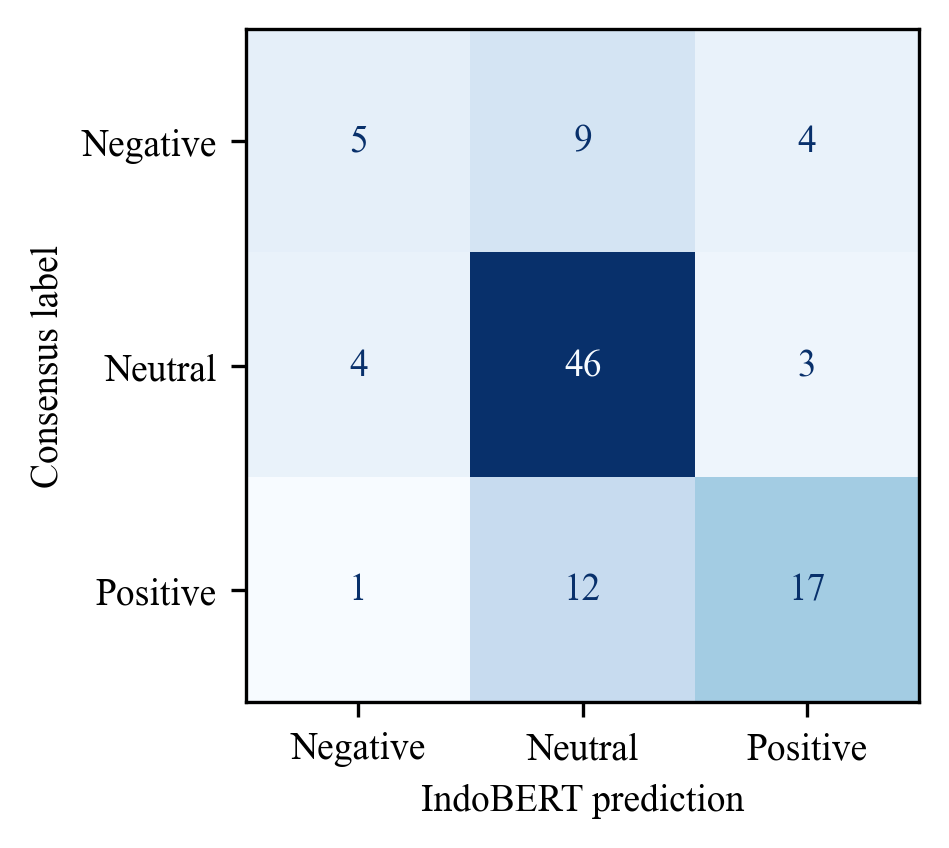

[[ 5  9  4]
 [ 4 46  3]
 [ 1 12 17]]


In [7]:
# ════ SEL F : EVALUASI UJI ════
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay)

uji['Prediksi'] = [ID2LABEL[i] for i in prediksi_proba(uji['Teks'].tolist()).argmax(1)]
rng = np.random.default_rng(SEED)

def evaluasi(ref, pred, nama):
    ref, pred = np.asarray(ref), np.asarray(pred)
    acc = accuracy_score(ref, pred)
    f1  = f1_score(ref, pred, labels=LBL, average='macro', zero_division=0)
    bs = np.array([(accuracy_score(ref[i], pred[i]),
                    f1_score(ref[i], pred[i], labels=LBL, average='macro', zero_division=0))
                   for i in (rng.integers(0, len(ref), len(ref)) for _ in range(2000))])
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    rep = classification_report(ref, pred, labels=LBL, zero_division=0, output_dict=True)
    print(f'\n══ IndoBERT vs {nama} (n = {len(ref)}) ══')
    print(f'Akurasi {acc:.3f} ({lo[0]:.3f}–{hi[0]:.3f}) | Macro-F1 {f1:.3f} ({lo[1]:.3f}–{hi[1]:.3f})')
    print(classification_report(ref, pred, labels=LBL, zero_division=0))
    return {'Acuan': nama, 'n': len(ref),
            'Akurasi': round(acc, 3), 'Akurasi_CI95': f'{lo[0]:.3f}–{hi[0]:.3f}',
            'MacroF1': round(f1, 3), 'MacroF1_CI95': f'{lo[1]:.3f}–{hi[1]:.3f}',
            **{f'Recall_{l}': round(rep[l]['recall'], 3) for l in LBL}}

k = (uji['Label_A'] == uji['Label_B']).values
tabel_val = pd.DataFrame([
    evaluasi(uji['Label_Auto'], uji['Prediksi'], 'Leksikon'),
    evaluasi(uji['Label_B'],    uji['Prediksi'], 'LLM'),
    evaluasi(uji['Label_A'],    uji['Prediksi'], 'Manusia'),
    evaluasi(uji.loc[k, 'Label_A'], uji.loc[k, 'Prediksi'], 'Konsensus manusia–LLM'),
])
print(f"\nCohen's κ manusia vs LLM: {cohen_kappa_score(uji['Label_A'], uji['Label_B']):.3f} "
      f"| judul konsensus: {k.sum()}/{len(uji)}")
print('\n' + tabel_val.to_string(index=False))
tabel_val.to_csv(DIR_OUT / 'tabel_validasi_indobert.csv', index=False, encoding='utf-8-sig')
uji.to_csv(DIR_OUT / 'prediksi_data_uji.csv', index=False, encoding='utf-8-sig')

# Fig. 2 artikel: confusion matrix terhadap label konsensus
cm = confusion_matrix(uji.loc[k, 'Label_A'], uji.loc[k, 'Prediksi'], labels=LBL)
with plt.rc_context({'font.family': 'Times New Roman', 'font.size': 9}):
    fig, ax = plt.subplots(figsize=(3.4, 2.9), dpi=300)
    ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Neutral', 'Positive']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_xlabel('IndoBERT prediction'); ax.set_ylabel('Consensus label')
    plt.tight_layout(); plt.savefig(DIR_GAMBAR / 'confusion_matrix_konsensus.png', dpi=600)
    plt.show()
print(cm)

## 🎯 SEL G — Skor Sentimen Seluruh Artikel

In [9]:
# ════ SEL G : PREDIKSI SEMUA ARTIKEL ════
proba = prediksi_proba(df_berita['Teks'].tolist())
df_hasil = df_berita.copy()
df_hasil[['P_Negatif', 'P_Netral', 'P_Positif']] = proba.round(4)
df_hasil['Skor_Sentimen']  = (proba[:, 2] - proba[:, 0]).round(4)   # S = P(+) − P(−) ∈ [−1, 1]
df_hasil['Confidence']     = proba.max(1).round(4)
df_hasil['Label_Sentimen'] = [ID2LABEL[i] for i in proba.argmax(1)]
df_hasil.to_csv(DIR_OUT / 'skor_sentimen_per_artikel.csv', index=False, encoding='utf-8-sig')
print(df_hasil['Label_Sentimen'].value_counts().reindex(LBL).to_string())
print(f'Skor: mean={df_hasil["Skor_Sentimen"].mean():+.3f}  std={df_hasil["Skor_Sentimen"].std():.3f}')

Label_Sentimen
Negatif     716
Netral     6465
Positif    2099
Skor: mean=+0.149  std=0.493


## 🧩 SEL H — Kesesuaian IndoBERT vs Leksikon pada Seluruh Korpus (bukan akurasi)

N = 9,280 | kesesuaian = 0.837 | κ = 0.666
                  IndoBERT_Negatif  IndoBERT_Netral  IndoBERT_Positif
Leksikon_Negatif               530              334                19
Leksikon_Netral                147             5461               306
Leksikon_Positif                39              670              1774


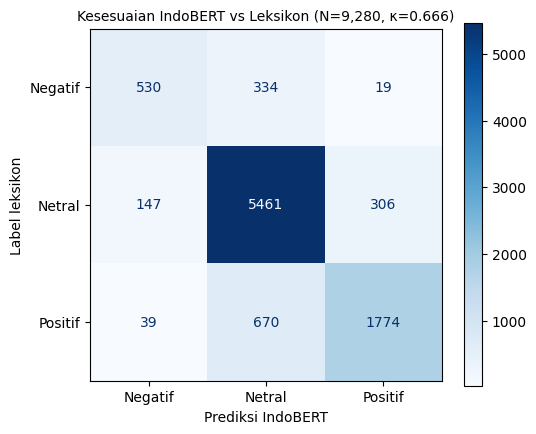

In [10]:
# ════ SEL H : AGREEMENT SELURUH KORPUS ════
agree = (df_hasil['Label_Auto'] == df_hasil['Label_Sentimen']).mean()
kappa = cohen_kappa_score(df_hasil['Label_Auto'], df_hasil['Label_Sentimen'], labels=LBL)
print(f'N = {len(df_hasil):,} | kesesuaian = {agree:.3f} | κ = {kappa:.3f}')
cm_all = pd.DataFrame(confusion_matrix(df_hasil['Label_Auto'], df_hasil['Label_Sentimen'], labels=LBL),
                      index=[f'Leksikon_{l}' for l in LBL], columns=[f'IndoBERT_{l}' for l in LBL])
print(cm_all.to_string())
cm_all.to_csv(DIR_OUT / 'tabel_kesesuaian_leksikon_seluruh_artikel.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_all.values, display_labels=LBL).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_xlabel('Prediksi IndoBERT'); ax.set_ylabel('Label leksikon')
ax.set_title(f'Kesesuaian IndoBERT vs Leksikon (N={len(df_hasil):,}, κ={kappa:.3f})', fontsize=10)
plt.tight_layout(); plt.savefig(DIR_GAMBAR / 'kesesuaian_leksikon_seluruh_artikel.png', dpi=300); plt.show()

## 📊 SEL I — Distribusi Sentimen per Emiten

Label_Sentimen  Positif  Netral  Negatif  Total  % Positif  % Netral  % Negatif
Kode_Emiten                                                                    
ADRO                547    1144      146   1837       29.8      62.3        7.9
ADMR                114     212       39    365       31.2      58.1       10.7
ITMG                252     307       92    651       38.7      47.2       14.1
PTBA                379    1376      133   1888       20.1      72.9        7.0
MEDC                286    1010      102   1398       20.5      72.2        7.3
AKRA                216     552       62    830       26.0      66.5        7.5
PGAS                305    1864      142   2311       13.2      80.7        6.1


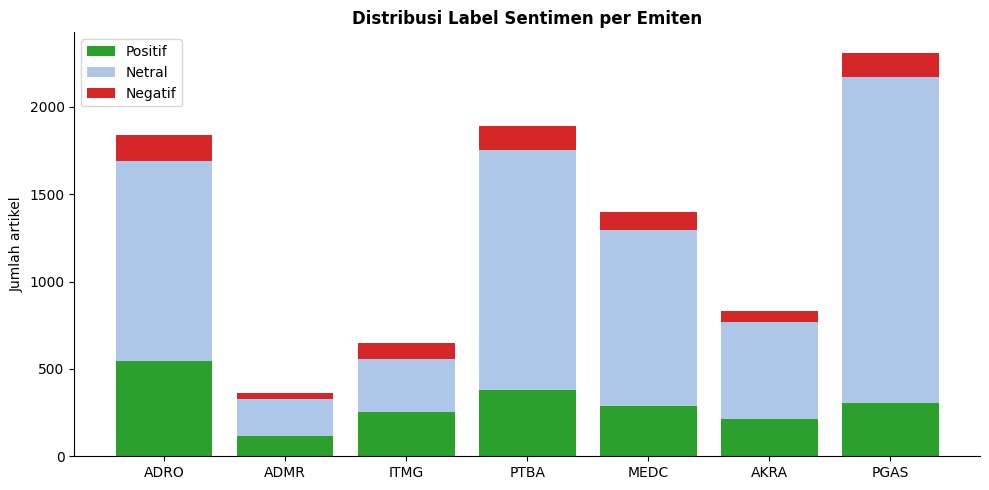

In [11]:
# ════ SEL I : DISTRIBUSI PER EMITEN ════
pivot = (pd.crosstab(df_hasil['Kode_Emiten'], df_hasil['Label_Sentimen'])
           .reindex(index=URUTAN_EMITEN, columns=['Positif', 'Netral', 'Negatif'], fill_value=0))
pivot['Total'] = pivot.sum(1)
for c in ['Positif', 'Netral', 'Negatif']:
    pivot[f'% {c}'] = (pivot[c] / pivot['Total'] * 100).round(1)
print(pivot.to_string())
pivot.to_csv(DIR_OUT / 'tabel_distribusi_sentimen_per_emiten.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(10, 5)); bawah = np.zeros(len(pivot))
for c, w in [('Positif', '#2ca02c'), ('Netral', '#aec7e8'), ('Negatif', '#d62728')]:
    ax.bar(pivot.index, pivot[c], bottom=bawah, label=c, color=w); bawah += pivot[c].values
ax.set_ylabel('Jumlah artikel'); ax.set_title('Distribusi Label Sentimen per Emiten', fontweight='bold')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(DIR_GAMBAR / 'distribusi_sentimen_per_emiten.png', dpi=300); plt.show()

## 📅 SEL J — Agregasi Harian, Pemetaan ke Hari Bursa, dan Forward-fill

In [12]:
# ════ SEL J : AGREGASI HARIAN ════
df_hasil['Tanggal'] = pd.to_datetime(df_hasil['Tanggal'], errors='coerce').dt.tz_localize(None).dt.normalize()

PATH_TEKNIKAL = DIR_PROCESSED / 'technical_features.csv'
assert PATH_TEKNIKAL.exists(), 'Jalankan PREP_01 dulu (technical_features.csv belum ada)'
hari = pd.to_datetime(sorted(pd.read_csv(PATH_TEKNIKAL, usecols=['Date'])['Date'].unique()))
print(f'Kalender bursa: {len(hari)} hari ({hari.min().date()} → {hari.max().date()})')

# Berita di hari non-bursa → hari bursa berikutnya
n_awal, tgl_asli = len(df_hasil), df_hasil['Tanggal'].copy()
pos = hari.searchsorted(df_hasil['Tanggal'].values, side='left')
valid = (pos < len(hari)) & df_hasil['Tanggal'].notna().values
df_hasil = df_hasil.loc[valid].copy(); df_hasil['Tanggal'] = hari[pos[valid]]
print(f'Digeser ke hari bursa berikutnya: {(df_hasil["Tanggal"] != tgl_asli.loc[df_hasil.index]).sum():,} '
      f'| dibuang (di luar periode): {n_awal - len(df_hasil):,}')

df_agg = (df_hasil.groupby(['Kode_Emiten', 'Tanggal'])
          .agg(Skor_Sentimen=('Skor_Sentimen', 'mean'), Skor_Sentimen_Std=('Skor_Sentimen', 'std'),
               Jumlah_Artikel=('Skor_Sentimen', 'count'))
          .reset_index())
df_agg['Skor_Sentimen_Std'] = df_agg['Skor_Sentimen_Std'].fillna(0); df_agg['Ada_Berita'] = 1

idx = pd.MultiIndex.from_product([URUTAN_EMITEN, hari], names=['Kode_Emiten', 'Tanggal'])
df_full = (pd.DataFrame(index=idx).reset_index()
             .merge(df_agg, on=['Kode_Emiten', 'Tanggal'], how='left')
             .sort_values(['Kode_Emiten', 'Tanggal']))
df_full['Ada_Berita']     = df_full['Ada_Berita'].fillna(0).astype(int)
df_full['Jumlah_Artikel'] = df_full['Jumlah_Artikel'].fillna(0).astype(int)
for c in ['Skor_Sentimen', 'Skor_Sentimen_Std']:               # hari tanpa berita: forward-fill
    df_full[c] = df_full.groupby('Kode_Emiten')[c].ffill().fillna(0.0)
print(f'Total hari-emiten: {len(df_full):,} | hari dengan berita: {df_full["Ada_Berita"].mean():.1%}')

Kalender bursa: 1074 hari (2022-01-03 → 2026-06-30)
Digeser ke hari bursa berikutnya: 1,079 | dibuang (di luar periode): 0
Total hari-emiten: 7,518 | hari dengan berita: 52.5%


## 📈 SEL K — Tren Sentimen

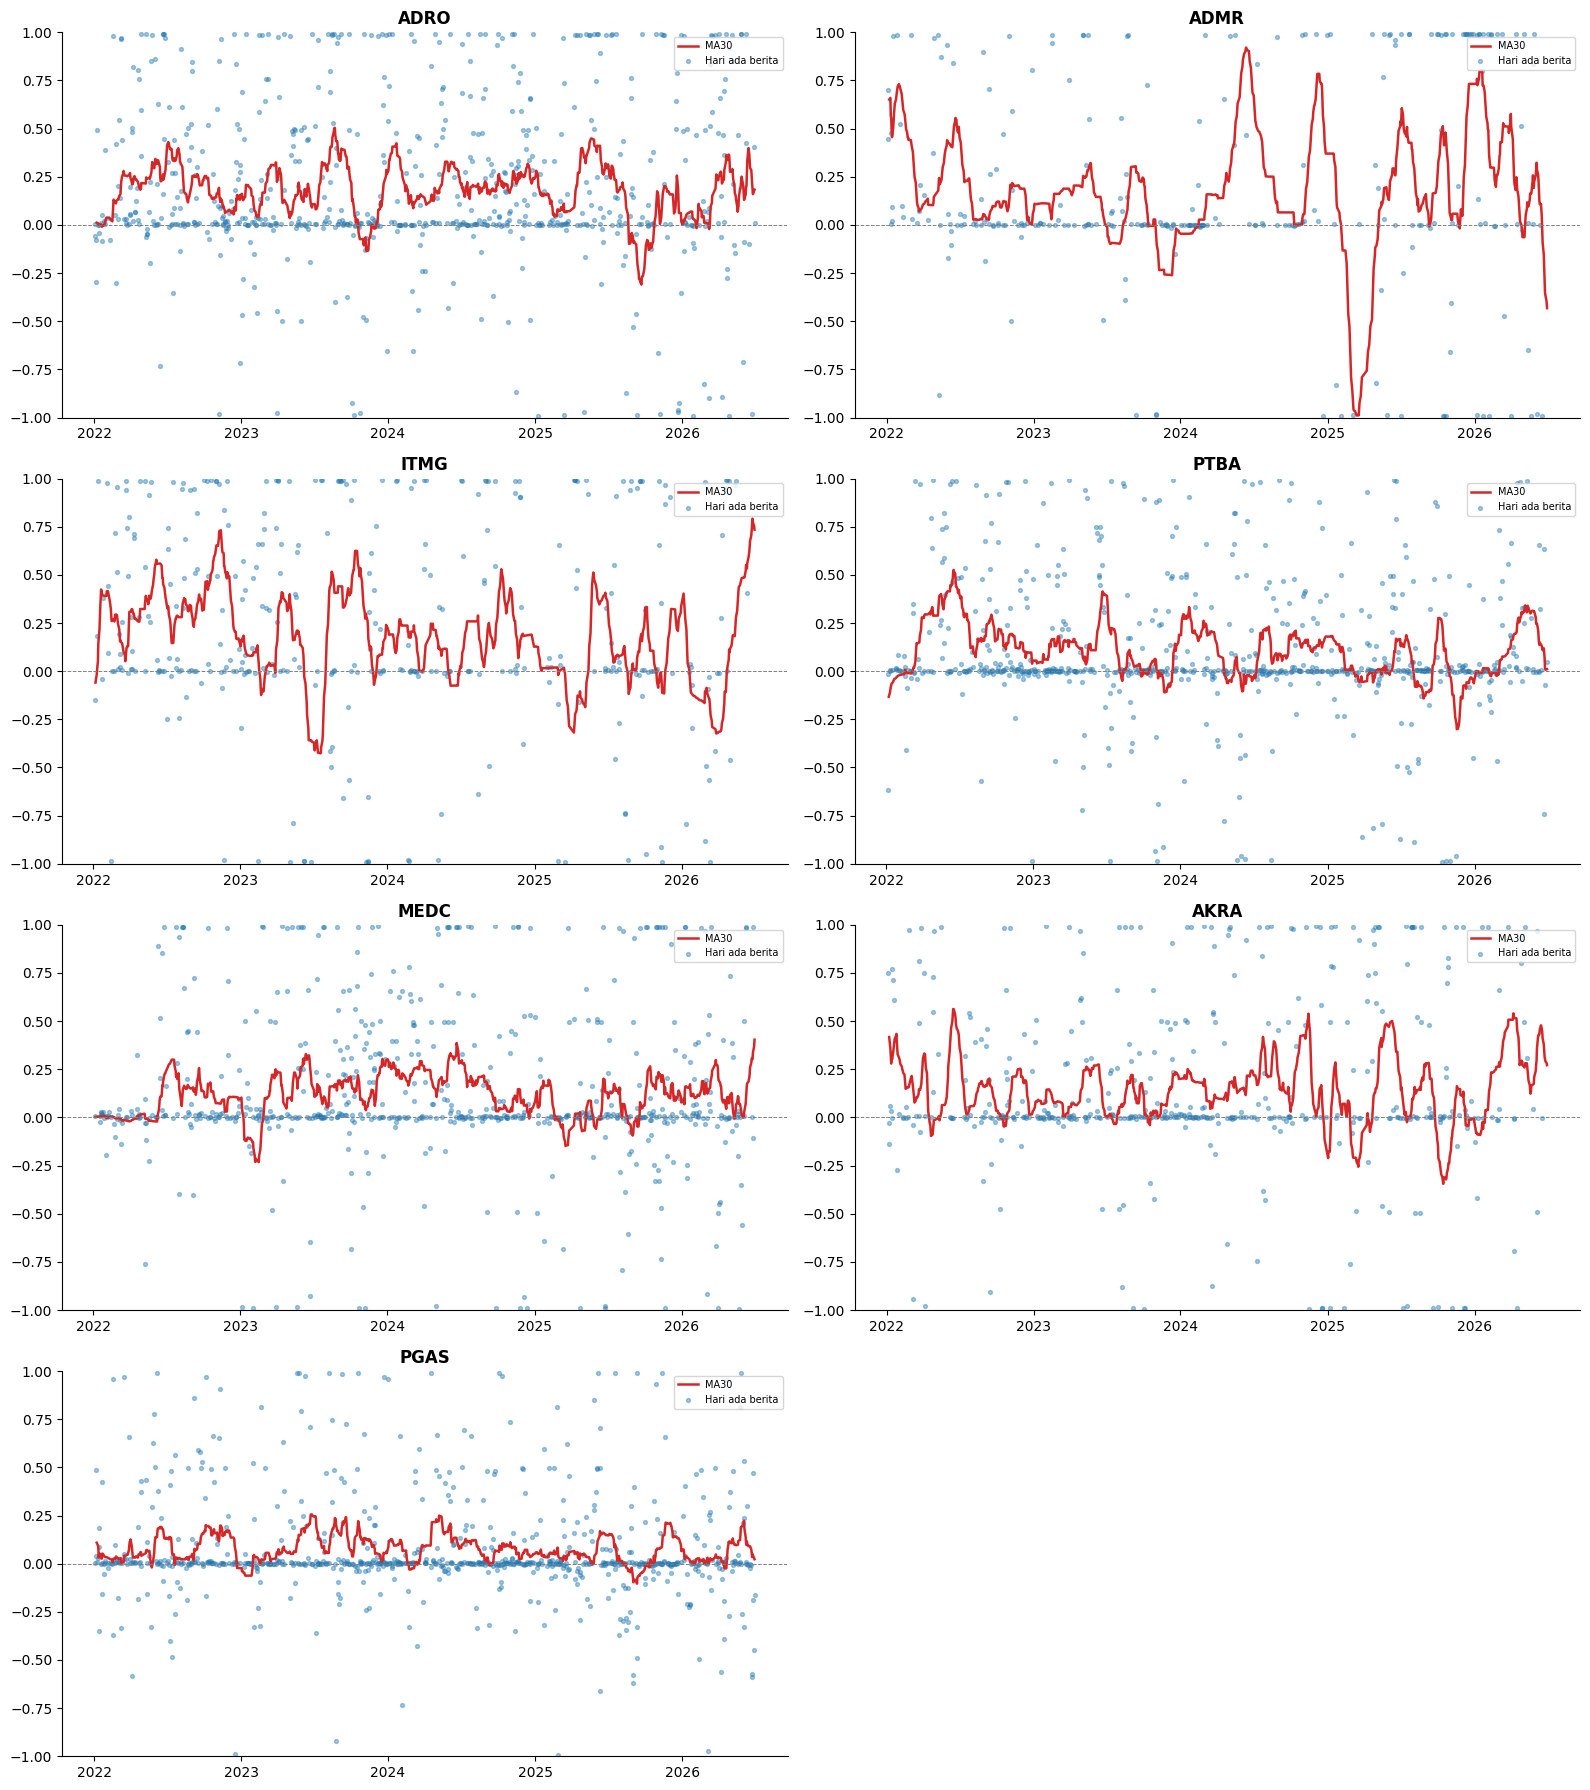

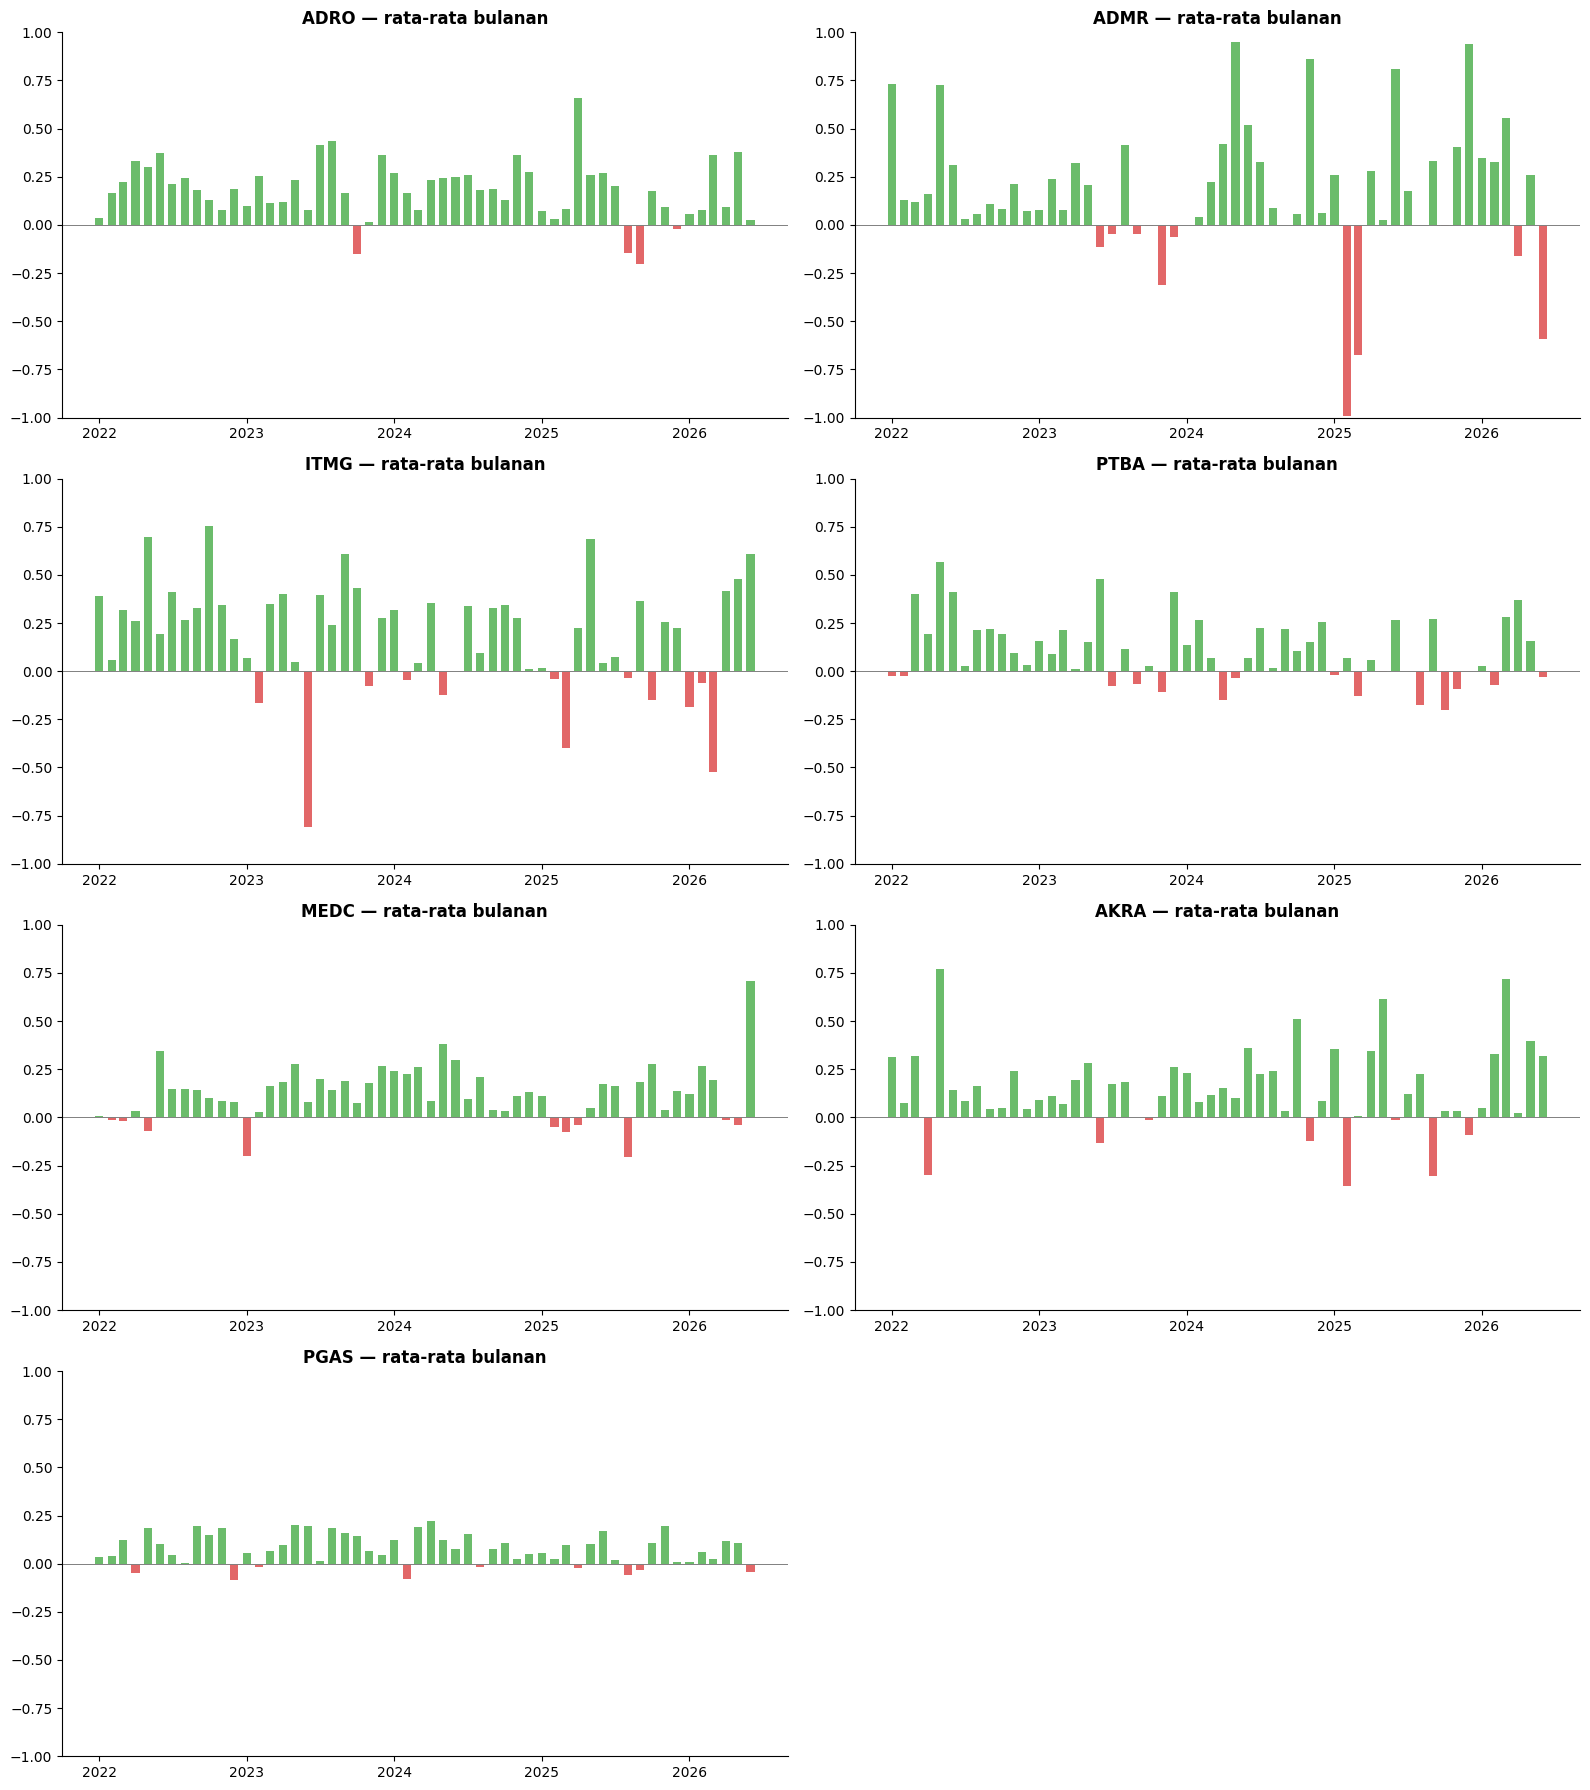

In [13]:
# ════ SEL K : TREN SENTIMEN HARIAN & BULANAN ════
fig, axes = plt.subplots(4, 2, figsize=(16, 18)); axes = axes.flatten()
for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].set_index('Tanggal'); ax = axes[i]
    ax.plot(g.index, g['Skor_Sentimen'].rolling(30, min_periods=5).mean(), lw=1.8, color='#d62728', label='MA30')
    hb = g[g['Ada_Berita'] == 1]
    ax.scatter(hb.index, hb['Skor_Sentimen'], s=8, color='#1f77b4', alpha=.4, label='Hari ada berita')
    ax.axhline(0, color='gray', ls='--', lw=.7); ax.set_ylim(-1, 1); ax.set_title(em, fontweight='bold')
    ax.legend(fontsize=7, loc='upper right'); ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].axis('off'); plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_harian.png', dpi=200, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(4, 2, figsize=(16, 18)); axes = axes.flatten()
for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].copy()
    agg = g.groupby(g['Tanggal'].dt.to_period('M'))['Skor_Sentimen'].mean(); x = agg.index.to_timestamp()
    ax = axes[i]; ax.bar(x, agg.values, width=20, color=np.where(agg.values >= 0, '#2ca02c', '#d62728'), alpha=.7)
    ax.axhline(0, color='gray', lw=.7); ax.set_ylim(-1, 1); ax.set_title(f'{em} — rata-rata bulanan', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].axis('off'); plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_bulanan.png', dpi=200, bbox_inches='tight'); plt.show()

## 💾 SEL L — Simpan X2 (siap digabung di PREP_03)

In [14]:
# ════ SEL L : SIMPAN X2 ════
df_final = (df_full[['Kode_Emiten', 'Tanggal', 'Skor_Sentimen', 'Skor_Sentimen_Std', 'Jumlah_Artikel', 'Ada_Berita']]
            .rename(columns={'Kode_Emiten': 'Emiten', 'Tanggal': 'Date', 'Skor_Sentimen': 'Sentiment_Mean',
                             'Skor_Sentimen_Std': 'Sentiment_Dispersion', 'Jumlah_Artikel': 'News_Count'})
            .sort_values(['Emiten', 'Date']).reset_index(drop=True))
df_final[['Sentiment_Mean', 'Sentiment_Dispersion']] = df_final[['Sentiment_Mean', 'Sentiment_Dispersion']].round(4)

assert df_final.isnull().sum().sum() == 0 and not df_final.duplicated(['Emiten', 'Date']).any()
for nama in ['skor_sentimen_harian.csv', 'sentiment_ready_for_merge.csv']:
    df_final.to_csv(DIR_PROCESSED / nama, index=False, encoding='utf-8-sig')
    df_final.to_csv(DIR_OUT / nama, index=False, encoding='utf-8-sig')   # salinan arsip v2
print(f'✅ {len(df_final):,} baris disimpan ke {DIR_PROCESSED}')
print('Kolom:', df_final.columns.tolist())
print(df_final.groupby('Emiten')['Sentiment_Mean'].agg(['mean', 'std', 'min', 'max']).round(3)
      .reindex(URUTAN_EMITEN).to_string())

✅ 7,518 baris disimpan ke E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed
Kolom: ['Emiten', 'Date', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
         mean    std    min    max
Emiten                            
ADRO    0.176  0.433 -0.992  0.992
ADMR    0.164  0.551 -0.993  0.992
ITMG    0.187  0.529 -0.992  0.992
PTBA    0.106  0.368 -0.990  0.992
MEDC    0.124  0.396 -0.992  0.992
AKRA    0.145  0.471 -0.992  0.992
PGAS    0.075  0.275 -0.991  0.991


## 🔍 SEL M — Perbandingan X2 Versi Leksikon (v1) vs Label Manusia (v2)

In [15]:
# ════ SEL M : PERBANDINGAN v1 vs v2 (untuk Response to Reviewers) ════
PATH_V1 = ROOT / '03_dataset_v1_leksikon' / 'processed' / 'skor_sentimen_harian.csv'
if PATH_V1.exists():
    v1 = pd.read_csv(PATH_V1, parse_dates=['Date'])
    m = v1.merge(df_final, on=['Emiten', 'Date'], suffixes=('_v1', '_v2'))
    m = m[m['Ada_Berita_v2'] == 1]
    kor = m.groupby('Emiten').apply(lambda g: g['Sentiment_Mean_v1'].corr(g['Sentiment_Mean_v2']))
    print('Korelasi Sentiment_Mean v1 vs v2 (hari dengan berita):')
    print(kor.reindex(URUTAN_EMITEN).round(3).to_string())
    print(f'Gabungan: {m["Sentiment_Mean_v1"].corr(m["Sentiment_Mean_v2"]):.3f}')
else:
    print('Backup v1 tidak ditemukan — lewati.')
print('\n➡️ Lanjut: PREP_03 (integrasi) → pemodelan XGBoost/LSTM → EVALUASI (DM) → SHAP → ABLATION → FORECAST H+1')

Korelasi Sentiment_Mean v1 vs v2 (hari dengan berita):
Emiten
ADRO    0.720
ADMR    0.802
ITMG    0.756
PTBA    0.702
MEDC    0.795
AKRA    0.735
PGAS    0.691
Gabungan: 0.747

➡️ Lanjut: PREP_03 (integrasi) → pemodelan XGBoost/LSTM → EVALUASI (DM) → SHAP → ABLATION → FORECAST H+1
